<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Line Charts**
**IBM Skills Network guided lab | Portfolio edition**

### Project Overview
This notebook explores how reported compensation and job-satisfaction measures vary across age groups and levels of work experience. Line charts make changes between ordered groups easier to see, but the meaning of each trend depends on how the data is prepared.

**Guiding question:** How do compensation and job-satisfaction measures differ across age and experience groups in the developer survey?

**Approach:** Load the survey data, prepare age and experience fields, summarize compensation and satisfaction, visualize five comparisons, and interpret each chart.

**Tools and methods:** Python, Pandas, Matplotlib, grouping, median and mean calculations, and interquartile-range (IQR) filtering.

*This notebook is based on an IBM Skills Network guided lab. The original code, saved charts, branding, and attribution are retained; the project explanations and interpretations have been added for portfolio readers.*

Estimated time needed: **30** minutes


### Objectives


In this lab you will perform the following:
- Track trends in compensation across age groups and specific age ranges.
- Analyze job satisfaction trends based on experience level.
- Explore and interpret line charts to identify patterns and trends.

### Setup: Working with the Database
**Install the needed libraries**


In [1]:
!pip install pandas
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 95.1 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 107.6 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
!pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



#### Step 1: Download the dataset


In [3]:
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv


--2026-10-15 11:53:01--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv       0%[                    ]       0  --.-KB/s               
survey-data.csv       1%[                    ]   2.95M  14.7MB/s               
survey-data.csv       6%[>                   ]   9.82M  24.5MB/s               
survey-data.csv       8%[>                   ]  12.43M  20.7MB/s               
survey-data.csv       8%[>                   ]  12.72M  12.1MB/s               
survey-data.csv       9%[>             

#### Step 2: Import necessary libraries and load the dataset


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load the data


In [ ]:
df = pd.read_csv("survey-data.csv")

#### Display the first few rows to understand the structure of the data


In [8]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Trends in Compensation Over Age Groups


##### 1. Line Chart of Median `ConvertedCompYearly` by Age Group


- Track how the median yearly compensation (ConvertedCompYearly) changes across different age groups.
- Use a line chart to visualize these trends.<br>
The code extracts a number from each age label, uses it as the position on the horizontal axis, and removes compensation values above the upper IQR threshold before calculating medians.

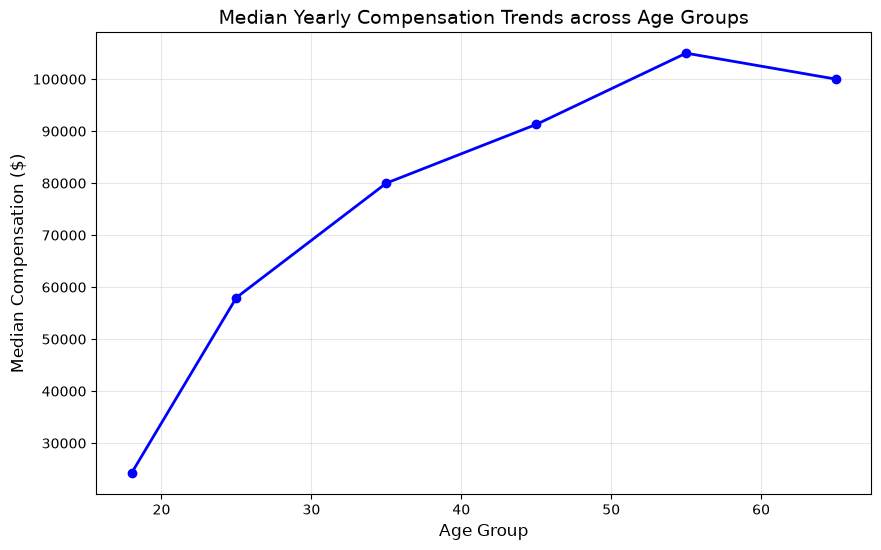

In [10]:
## Write your code here
df_t1 = df.dropna(subset=['Age', 'ConvertedCompYearly']).copy()
df_t1['Age_numeric'] = pd.to_numeric(df_t1['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t1 = df_t1.dropna(subset=['Age_numeric'])

Q1 = df_t1['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t1['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t1_clean = df_t1[df_t1['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

age_trends = df_t1_clean.groupby('Age_numeric')['ConvertedCompYearly'].median().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(age_trends['Age_numeric'], age_trends['ConvertedCompYearly'], marker='o', color='b', linewidth=2)
plt.title('Median Yearly Compensation Trends across Age Groups', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Median Compensation ($)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

The saved chart shows median reported annual compensation increasing from approximately $25,000 in the youngest displayed category to $58,000 at the next category and $80,000-$91,000 in the middle-age categories. It peaks at roughly $105,000 for the category beginning at age 55, before easing to around $100,000 in the oldest displayed category.

**Interpretation:** Older age categories generally have higher median compensation in this filtered sample, although the increase is not continuous.

##### 2. Line Chart of Median `ConvertedCompYearly` for Ages 25 to 45


For a closer look, plot a line chart focusing on the median compensation for respondents between ages 25 and 45.<br>
This chart focuses on three age categories, represented by their lower bounds: 25, 35, and 45. The line connects category-level medians. It does not track the same people as they get older, so it should not be interpreted as individual salary growth.


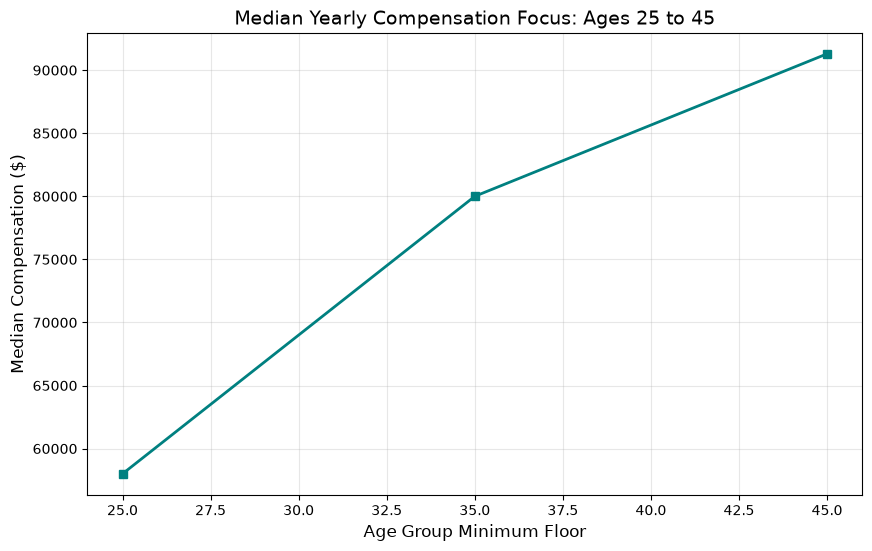

In [14]:
## Write your code here
df_t2 = df.dropna(subset=['Age', 'ConvertedCompYearly']).copy()
df_t2['Age_numeric'] = pd.to_numeric(df_t2['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_subset = df_t2[(df_t2['Age_numeric'] >= 25) & (df_t1['Age_numeric'] <= 45)].copy()

Q1 = df_subset['ConvertedCompYearly'].quantile(0.25)
Q3 = df_subset['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_subset_clean = df_subset[df_subset['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

subset_trends = df_subset_clean.groupby('Age_numeric')['ConvertedCompYearly'].median().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(subset_trends['Age_numeric'], subset_trends['ConvertedCompYearly'], marker='s', color='teal', linewidth=2)
plt.title('Median Yearly Compensation Focus: Ages 25 to 45', fontsize=14)
plt.xlabel('Age Group Minimum Floor', fontsize=12)
plt.ylabel('Median Compensation ($)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

The saved chart rises from approximately $58,000 for the category beginning at age 25 to $80,000 at age 35 and $91,000 at age 45. The increase is larger between the first two categories than between the second and third.

**Interpretation:** Among the displayed age groups, the filtered median compensation is higher in older categories. This suggests a possible relationship between age-related career progression and pay, but age itself is not established as the cause.

### Task 2: Trends in Job Satisfaction by Experience Level



##### 1. Line Chart of Job Satisfaction (`JobSatPoints_6`) by Experience Level



- Use a column that approximates experience level to analyze how job satisfaction changes with experience.
- If needed, substitute an available experience-related column for `Experience`.

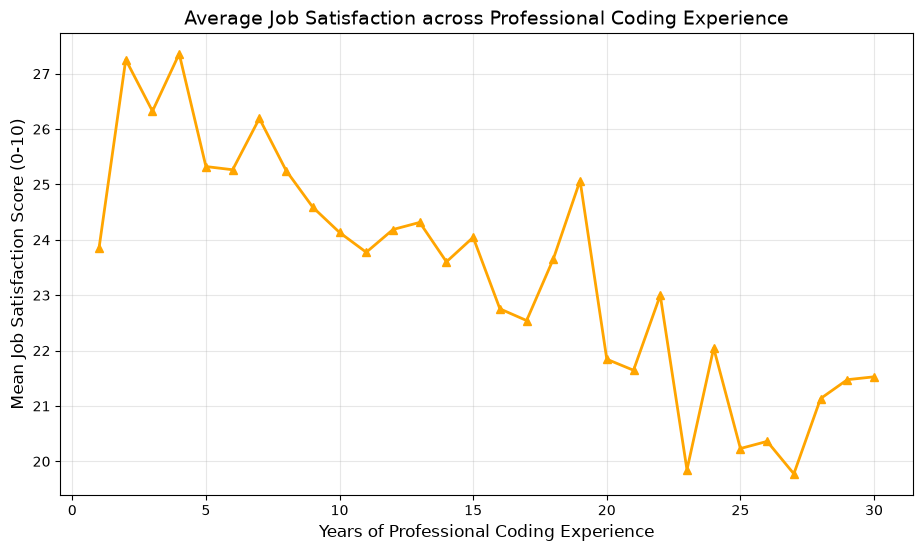

In [15]:
## Write your code here
df_t3 = df.dropna(subset=['YearsCodePro', 'JobSatPoints_6']).copy()
df_t3['Experience_Years'] = pd.to_numeric(df_t3['YearsCodePro'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t3['JobSatPoints_6'] = df_t3['JobSatPoints_6'].astype(int)
df_t3 = df_t3.dropna(subset=['Experience_Years'])

Q1 = df_t3['Experience_Years'].quantile(0.25)
Q3 = df_t3['Experience_Years'].quantile(0.75)
IQR = Q3 - Q1
df_t3_clean = df_t3[df_t3['Experience_Years'] <= (Q3 + 1.5 * IQR)]
sat_trends = df_t3_clean.groupby('Experience_Years')['JobSatPoints_6'].mean().reset_index()

plt.figure(figsize=(11, 6))
plt.plot(sat_trends['Experience_Years'], sat_trends['JobSatPoints_6'], marker='^', color='orange', linewidth=2)
plt.title('Average Job Satisfaction across Professional Coding Experience', fontsize=14)
plt.xlabel('Years of Professional Coding Experience', fontsize=12)
plt.ylabel('Mean Job Satisfaction Score (0-10)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

The chart starts at approximately 24 for respondents with zero reported years of professional coding experience, rises above 27 in some early-career groups, and then generally declines through later experience levels. Around 20–30 years, many plotted averages lie between 20 and 23, although the line fluctuates and includes occasional increases.

**Interpretation:** The saved values suggest a downward pattern in the specific survey measure plotted as professional coding experience increases.

### Task 3: Trends in Job Satisfaction and Compensation by Experience


##### 1.Line Chart of Median ConvertedCompYearly Over Experience Level
- This line chart will track how median compensation (`ConvertedCompYearly`) changes with increasing experience.
- Use a column such as `WorkExp` or another relevant experience-related column.

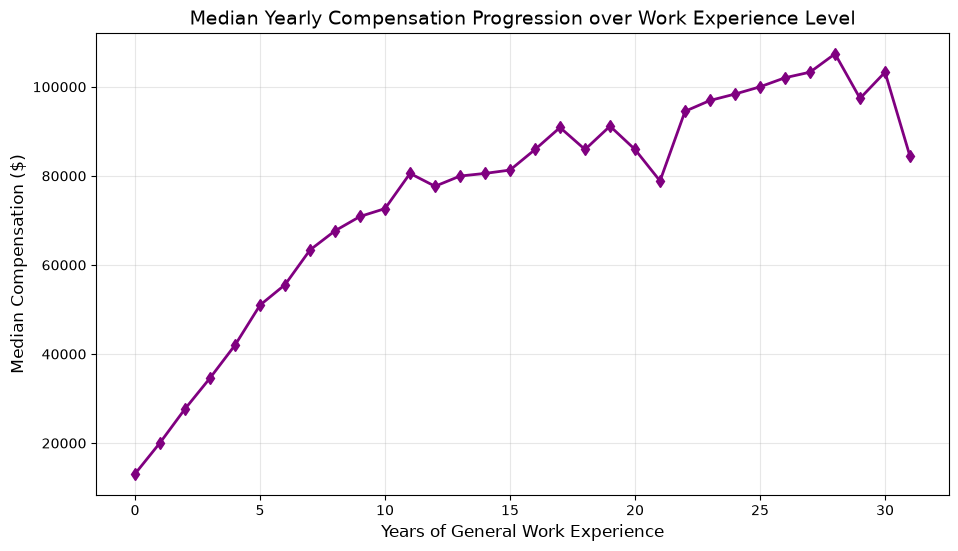

In [16]:
## Write your code here
df_t4 = df.dropna(subset=['WorkExp', 'ConvertedCompYearly']).copy()

Q1_exp = df_t4['WorkExp'].quantile(0.25)
Q3_exp = df_t4['WorkExp'].quantile(0.75)
IQR_exp = Q3_exp - Q1_exp
df_t4 = df_t4[(df_t4['WorkExp'] >= Q1_exp - 1.5 * IQR_exp) & (df_t4['WorkExp'] <= Q3_exp + 1.5 * IQR_exp)]

Q1_comp = df_t4['ConvertedCompYearly'].quantile(0.25)
Q3_comp = df_t4['ConvertedCompYearly'].quantile(0.75)
IQR_comp = Q3_comp - Q1_comp
df_t4_clean = df_t4[df_t4['ConvertedCompYearly'] <= (Q3_comp + 1.5 * IQR_comp)]
comp_exp_trends = df_t4_clean.groupby('WorkExp')['ConvertedCompYearly'].median().reset_index()

plt.figure(figsize=(11, 6))
plt.plot(comp_exp_trends['WorkExp'], comp_exp_trends['ConvertedCompYearly'], marker='d', color='purple', linewidth=2)
plt.title('Median Yearly Compensation Progression over Work Experience Level', fontsize=14)
plt.xlabel('Years of General Work Experience', fontsize=12)
plt.ylabel('Median Compensation ($)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

The saved line increases steeply from approximately $13,000 at zero years of general work experience to around $65,000 by seven years. It then climbs more gradually, reaching roughly $80,000 by 11-15 years. For respondents with more than 20 years, median compensation often falls in the $95,000-$107,000 range, although there are visible dips and rebounds.

**Interpretation:** The strongest rise appears in the earlier experience groups, followed by slower growth and greater variation.

##### 2.Line Chart of Job Satisfaction (`JobSatPoints_6`) Across Experience Levels
- Create a line chart to explore trends in job satisfaction (`JobSatPoints_6`) based on experience level.
- This chart will provide insight into how satisfaction correlates with experience over time

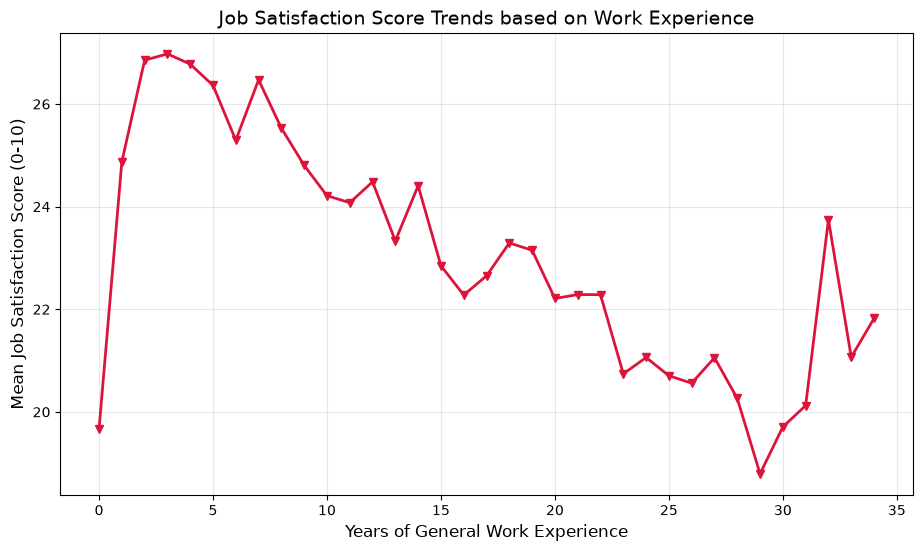

In [17]:
## Write your code here
df_t5 = df.dropna(subset=['WorkExp', 'JobSatPoints_6']).copy()
df_t5['JobSatPoints_6'] = df_t5['JobSatPoints_6'].astype(int)

Q1 = df_t5['WorkExp'].quantile(0.25)
Q3 = df_t5['WorkExp'].quantile(0.75)
IQR = Q3 - Q1
df_t5_clean = df_t5[(df_t5['WorkExp'] >= Q1 - 1.5 * IQR) & (df_t5['WorkExp'] <= Q3 + 1.5 * IQR)]

sat_exp_trends = df_t5_clean.groupby('WorkExp')['JobSatPoints_6'].mean().reset_index()

plt.figure(figsize=(11, 6))
plt.plot(sat_exp_trends['WorkExp'], sat_exp_trends['JobSatPoints_6'], marker='v', color='crimson', linewidth=2)
plt.title('Job Satisfaction Score Trends based on Work Experience', fontsize=14)
plt.xlabel('Years of General Work Experience', fontsize=12)
plt.ylabel('Mean Job Satisfaction Score (0-10)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

The saved chart rises from just under 20 at zero years to approximately 27 in the first few experience groups. It then shows a broad downward pattern, with many values around 22-24 in the middle of the range and a low near 19 around 29 years. The line rebounds at some later experience levels.

**Interpretation:** The plotted JobSatPoints_6 averages vary considerably, but the overall direction across much of the range is downward

### Key Findings
- Median compensation increases across most age categories in the filtered survey data, peaking around the age category beginning at 55 before declining slightly in the oldest displayed category.
- The focused age comparison also shows higher median compensation in older categories, from roughly $58,000 at the category beginning at 25 to $91,000 at 45.
- Compensation rises strongly across early years of general work experience, then increases more gradually and fluctuates in later experience groups.
- The JobSatPoints_6 measure tends to decline across much of the experience range, but its values are inconsistent with the chart's 0-10 axis labels. The variable must be verified before making conclusions about overall job satisfaction.
- These are comparisons between survey groups, not longitudinal career histories. The charts do not follow individual developers over time.

### Limitations and Next Steps
The dataset represents survey respondents rather than the entire developer workforce. Age is recorded in categories, but the code extracts a numerical lower bound. Different charts apply different IQR-based filters, which can affect comparability. Compensation comparisons may also reflect differences in geography, roles, and reporting conventions. The focused age-chart filter references a DataFrame from an earlier task and should be corrected and tested.

Most importantly, the JobSatPoints_6 plots show values above 20 while labeling the scale 0-10. Before publishing claims about satisfaction, I would check the original survey documentation, confirm the intended field, and regenerate the charts with accurate labels.

### Skills Demonstrated
- Data preparation: Converting survey responses into usable numeric groups and filtering extreme values.
- Statistical summaries: Comparing means and medians across age and experience groups.
- Visualization: Creating and interpreting five line charts with Matplotlib.
- Analytical judgment: Identifying misleading axis labels, filter inconsistencies, and the limits of cross-sectional comparisons.
- Communication: Presenting evidence-based findings in concise language for non-technical readers.

### Summary


In this lab, you explored essential data visualization techniques with a focus on analyzing trends using line charts. You learned to:
- Visualize the distribution of compensation across age groups to understand salary trends.
- Track changes in median compensation over various experience levels, identifying how earnings progress with experience.
- Examine trends in job satisfaction by experience, revealing how satisfaction varies throughout a developer's career.

These analyses allow for a deeper understanding of how factors like age and experience influence job satisfaction and compensation. By using line charts, you gained insights into continuous data patterns, which are invaluable for interpreting professional trends in the developer community.


### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
